# Double-well: an additional validation example on simulated data

This example is **not one of the paper's experiments**. It is an extra check of the stitching method on a system whose truth we know exactly: a one-dimensional particle system in a double-well potential, simulated by us. Because the potential, the diffusion coefficient and every trajectory are known, we can ask whether the method recovers the *force* and reproduces the *distributions* at times it never saw.

The paper's own experiments (wavy valley, synthetic potentials, RNA, CIS, chiral) are listed under `experiments/paper_reproduction/`.

This notebook **does not simulate and does not train**.
- The data come from a saved dataset (`dw-001`), loaded by ID. Reopening the notebook or changing a training setting can never produce a different dataset. A new dataset is made only by the explicit command `data.py generate`, which gets a new ID.
- The learned model comes from a finished run of `run.py train` / `eval` (section 7).

In [1]:
# ═══ [SETUP] ═══
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch

HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "wgf").is_dir())
EXP = ROOT / "experiments" / "validation" / "double_well"
sys.path[:0] = [str(ROOT), str(EXP)]
from data import load                                   # loads a saved dataset; never simulates
from wgf import potentials as P
from wgf.runs import load_model

torch.set_default_dtype(torch.float64)
DATASET = "dw-001"       # the saved dataset this notebook reads
SPLIT = "interleaved"    # which held-out split to show in the figures

## 1 · How the data were generated

Each trajectory follows the overdamped Langevin equation (the particle form of the Wasserstein gradient flow of $\mathcal F(\rho)=\int V\,d\rho+\beta\int\rho\log\rho$):

$$dX_t = -\nabla V(X_t)\,dt + \sqrt{2\beta}\,dB_t,\qquad V(x)=\tfrac12\,(|x|-c)^2,\quad c=7,\quad \beta=1,\qquad X_0\sim\mathcal N(0,1).$$

It is integrated with the Euler–Maruyama step

$$X^{n+1}=X^n-\Delta t\,\nabla V(X^n)+\sqrt{2\beta\,\Delta t}\;\varepsilon^n,\qquad \varepsilon^n\sim\mathcal N(0,1),$$

using equal sub-steps $\Delta t\le 0.01$ between consecutive observation times. The run is **paired**: row $i$ is the same trajectory at every observation time. One seeded random generator drives the initial draw, the noise, and then the split of trajectories into training and test. The cell below loads the saved arrays and prints the settings that were stored with them.

In [2]:
# ═══ [DATA] load the saved dataset (no simulation) ═══
ds = load(DATASET)
s = ds.meta["settings"]
print(f"dataset {ds.id}: {ds.meta['description']}")
print(f"  samples X {tuple(ds.X.shape)} = (observation time, trajectory, dimension); trajectory IDs {ds.traj_ids[0].item()}..{ds.traj_ids[-1].item()}")
print(f"  potential          {s['potential']['formula']}, c = {s['potential']['c']}")
print(f"  initial law        {s['initial_distribution']}")
print(f"  diffusion          beta = {s['diffusion']['beta']}, sigma = sqrt(2 beta) = {s['diffusion']['sigma']:.4f}")
print(f"  integration        {s['integration']['method']}, step {s['integration']['step_sizes']} (<= {s['integration']['dt_max']})")
print(f"  observation times  {s['observation_times']['n']} on [0, {s['observation_times']['T']}]: {[round(t, 3) for t in ds.times.tolist()]}")
print(f"  seeds              {ds.meta['seeds']}")
print(f"  hashes             samples {ds.meta['samples_sha256'][:12]}..., splits {ds.meta['splits_sha256'][:12]}...")

dataset dw-001: seed 0, default settings: the data behind the 2026-10-26 double-well results
  samples X (20, 2000, 1) = (observation time, trajectory, dimension); trajectory IDs 0..1999
  potential          V(x) = (|x| - c)^2 / 2, c = 7.0
  initial law        N(0, 1)
  diffusion          beta = 1.0, sigma = sqrt(2 beta) = 1.4142
  integration        Euler-Maruyama (wgf.sim.em_step), step [0.009569377990431] (<= 0.01)
  observation times  20 on [0, 4.0]: [0.0, 0.211, 0.421, 0.632, 0.842, 1.053, 1.263, 1.474, 1.684, 1.895, 2.105, 2.316, 2.526, 2.737, 2.947, 3.158, 3.368, 3.579, 3.789, 4.0]
  seeds              {'data_generation': 0, 'splits': 'no separate seed: the trajectory permutation and trickle subsets continue the data-generation generator after the simulation (as double_well_regimes)'}
  hashes             samples e1e314ff2585..., splits 8f8e79d06e71...


## 2 · The true potential and its force

$V$ has two wells at $x=\pm7$ and a barrier at $x=0$. Its gradient $\nabla V(x)=x-7\,\mathrm{sign}(x)$ jumps from $+7$ to $-7$ at the barrier. A smooth network $V_\theta$ cannot reproduce that jump exactly, so force errors are expected to concentrate near $x=0$. The drift of the SDE is $-\nabla V$: it pushes particles away from $0$ and toward the nearest well.

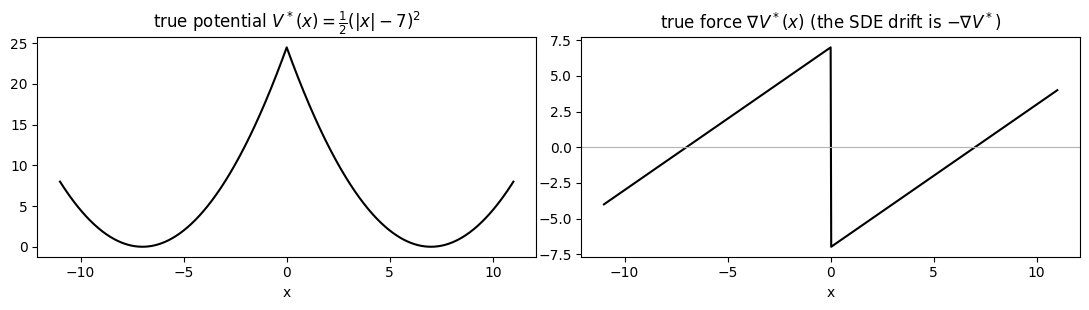

In [3]:
x = torch.linspace(-11, 11, 801)[:, None]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(x, P.double_well_1d(x), "k"); ax[0].set(title="true potential $V^*(x)=\\frac{1}{2}(|x|-7)^2$", xlabel="x")
ax[1].plot(x, P.grad_double_well_1d(x), "k"); ax[1].axhline(0, c="0.7", lw=0.8)
ax[1].set(title="true force $\\nabla V^*(x)$ (the SDE drift is $-\\nabla V^*$)", xlabel="x")
fig.tight_layout()

## 3 · A few simulated SDE trajectories

The dataset stores 12 trajectories (IDs 0–11) at **every integration step**, purely for this figure; the other trajectories are stored at the observation times only. The vertical lines are the observation times of the split chosen above: solid for **training** times, dashed for **held-out test** times. Each curve is one realisation of the noise. Each one falls into a well at random, and nothing about where an individual path ends up is a target for the model.

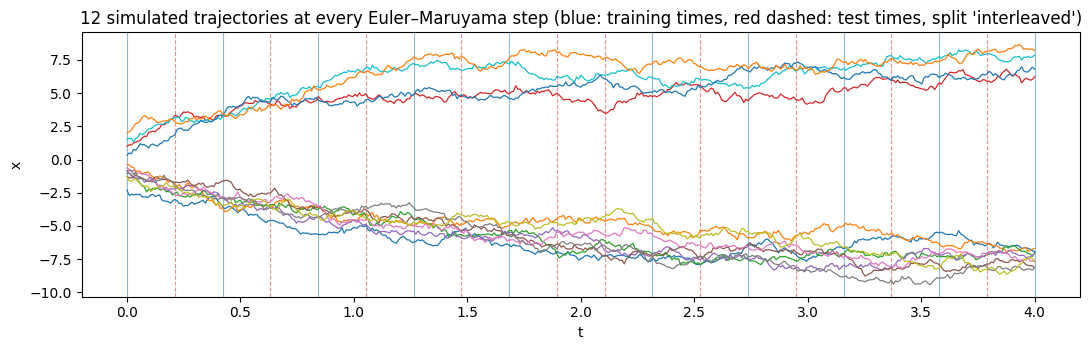

In [4]:
sp = ds.split(SPLIT)
t_train = [ds.times[j].item() for j in sp["train_time_idx"]]
t_test = [ds.times[j].item() for j in sp["test_time_idx"]]

def mark_times(a):
    for t in t_train: a.axvline(t, c="tab:blue", lw=0.8, alpha=0.5)
    for t in t_test: a.axvline(t, c="tab:red", lw=0.8, ls="--", alpha=0.5)

fig, a = plt.subplots(figsize=(11, 3.6))
mark_times(a)
for i in range(ds.paths["X"].shape[1]):
    a.plot(ds.paths["times"], ds.paths["X"][:, i, 0], lw=0.9)
a.set(xlabel="t", ylabel="x", title=f"{ds.paths['X'].shape[1]} simulated trajectories at every Euler–Maruyama step "
      f"(blue: training times, red dashed: test times, split '{SPLIT}')")
fig.tight_layout()

## 4 · The distributions over time

Here are all 2000 trajectories at the 20 observation times. On the left, each column is a histogram of one snapshot, with the time axis marked as above. On the right are a few snapshots drawn as densities. The mass leaves $\mathcal N(0,1)$, splits roughly half and half between the two wells by about $t\approx1$, and then relaxes toward the stationary law $\propto e^{-V/\beta}$, a mixture of two $\mathcal N(\pm7,1)$.

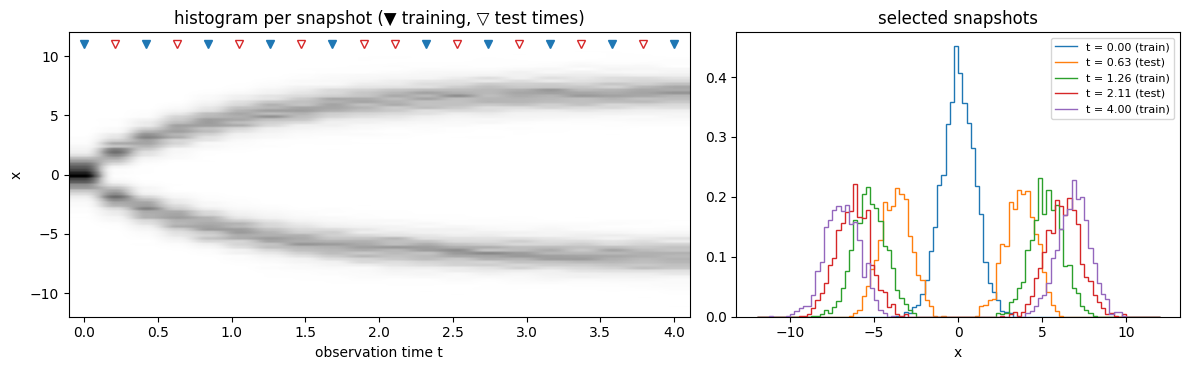

In [5]:
edges = torch.linspace(-12, 12, 97)
H = torch.stack([torch.histc(ds.X[j, :, 0], bins=96, min=-12, max=12) for j in range(len(ds.times))]) / (ds.X.shape[1] * (edges[1] - edges[0]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
dt = (ds.times[1] - ds.times[0]).item()
ax[0].imshow(H.T, origin="lower", aspect="auto", cmap="Greys",
             extent=[ds.times[0].item() - dt / 2, ds.times[-1].item() + dt / 2, -12, 12])
for t in t_train: ax[0].plot([t], [11], "v", c="tab:blue", ms=6)
for t in t_test: ax[0].plot([t], [11], "v", c="tab:red", mfc="none", ms=6)
ax[0].set(xlabel="observation time t", ylabel="x", title="histogram per snapshot (▼ training, ▽ test times)")
for j in (0, 3, 6, 10, 19):
    ax[1].stairs(H[j], edges, label=f"t = {ds.times[j]:.2f} ({'train' if j in sp['train_time_idx'] else 'test'})")
ax[1].set(xlabel="x", title="selected snapshots"); ax[1].legend(fontsize=8)
fig.tight_layout()

## 5 · Observation times are not the model's time grid

There are two different sets of times, and it helps to keep them apart.

- **Observation times** $s_1,\dots,s_{20}$ are when the simulation was *measured*, and they belong to the data. A split divides them into training times, whose snapshots the model is fitted to, and test times, which are held out for evaluation. Each observation time also has its own cells: training trajectories only for training, test trajectories only for evaluation.
- **The model's internal grid** $t_1<\dots<t_K$ ($K=50$, equally spaced from the first to the last training time) is where the model keeps its $N=100$ particle positions $X_{k,\cdot}$. Nothing is observed at these nodes. They discretise the particle paths, and the velocity residual $\mathcal R$ is a sum over consecutive nodes.

The model's density at an observation time $s$ is the KDE of the centres linearly interpolated between the two grid nodes around $s$. Training times and test times alike usually fall *between* grid nodes. The data enter the loss only through $-\log\rho_{s}(y)$ at the training observation times.

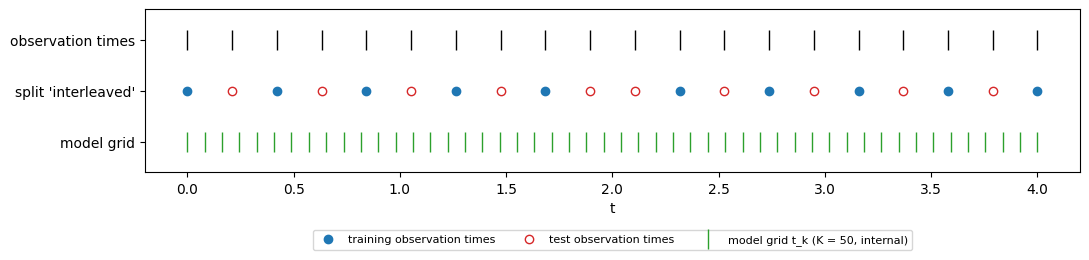

In [6]:
K = 50
t_grid = torch.linspace(t_train[0], t_train[-1], K)
fig, a = plt.subplots(figsize=(11, 2.9))
a.plot(ds.times, [2] * len(ds.times), "|", c="k", ms=14)
a.plot(t_train, [1] * len(t_train), "o", c="tab:blue", label="training observation times")
a.plot(t_test, [1] * len(t_test), "o", c="tab:red", mfc="none", label="test observation times")
a.plot(t_grid, [0] * K, "|", c="tab:green", ms=14, label=f"model grid t_k (K = {K}, internal)")
a.set(yticks=[0, 1, 2], yticklabels=["model grid", f"split '{SPLIT}'", "observation times"], xlabel="t", ylim=(-0.6, 2.6))
a.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3); fig.tight_layout()

## 6 · The three held-out splits

Every split keeps the first and last observation times for training, so the model only ever interpolates in time. All splits use the same partition of trajectories: 1000 for training and 1000 for testing, disjoint. Test cells therefore never share a trajectory, or its random choice of well, with a training cell. There is no validation part: nothing is tuned or selected on held-out data. Within a split, three regimes decide how much of the training part the model sees:
- **dense**: every training time, all training trajectories;
- **terminal**: only the first and last training time;
- **trickle**: every training time, 10 training trajectories, a different subset at each time.

The checks below are asserted, not just printed. They confirm that every cell a regime trains on is a (training time, training trajectory) pair. The path initialisation and the bandwidth use only these cells too: they are computed from the first and last training snapshot of the regime. `tests/test_datastore.py` replaces every held-out sample with NaN and confirms that training is bit-for-bit unchanged.

In [7]:
for name, s_ in ds.splits.items():
    tr, te = set(s_["train_traj_ids"]), set(s_["test_traj_ids"])
    assert not tr & te and not set(s_["train_time_idx"]) & set(s_["test_time_idx"])
    cells = {}
    for r in s_["regimes"]:
        idx, ids = ds.regime_cells(name, r)
        assert set(idx) <= set(s_["train_time_idx"]) and all(set(i) <= tr for i in ids)
        cells[r] = sum(map(len, ids))
    print(f"{ds.split_id(name):18} train times {s_['train_time_idx']}\n{'':18} test times  {s_['test_time_idx']}\n"
          f"{'':18} trajectories {len(tr)} train / {len(te)} test / {len(s_['val_traj_ids'])} val;  "
          f"training cells per regime {cells}")

dw-001:interleaved train times [0, 2, 4, 6, 8, 11, 13, 15, 17, 19]
                   test times  [1, 3, 5, 7, 9, 10, 12, 14, 16, 18]
                   trajectories 1000 train / 1000 test / 0 val;  training cells per regime {'dense': 10000, 'terminal': 2000, 'trickle': 100}
dw-001:midpoint    train times [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 19]
                   test times  [1, 3, 5, 7, 9, 11, 13, 15, 17]
                   trajectories 1000 train / 1000 test / 0 val;  training cells per regime {'dense': 11000, 'terminal': 2000, 'trickle': 110}
dw-001:coarse      train times [0, 4, 8, 12, 16, 19]
                   test times  [1, 2, 3, 5, 6, 7, 9, 10, 11, 13, 14, 15, 17, 18]
                   trajectories 1000 train / 1000 test / 0 val;  training cells per regime {'dense': 6000, 'terminal': 2000, 'trickle': 60}


## 7 · Comparing the learned model with the simulation

The model is compared with the simulation through **distributions** and **forces**, never through individual paths:

- **Distributions.** At every held-out test time, the model's density, or samples from it, is compared with the test cells by exact 1-D $W_1$ and $W_2$. The same is done for an independent SDE rollout of the learned force, for the OT-interpolation baseline, and for references that use the true potential.
- **Forces.** $c_V\nabla V_\theta$ is compared with $\nabla V^*$ on the test cells and on a grid.
- **Paths are not pointwise targets.** The stitching model has 100 particles whose KDE has to match each snapshot. Its particle paths are a smooth transport that is consistent with the fitted dynamics. A simulated path is one noisy realisation, and the data are unpaired from the model's point of view, so there is no correspondence between particle $k$ and trajectory $i$ to compare.

The cell below reads a finished run's saved files (`metrics.json` and a checkpoint) and does not train or evaluate anything. Make one with:

```bash
.venv/bin/python experiments/validation/double_well/run.py train --split interleaved --epochs 200
.venv/bin/python experiments/validation/double_well/run.py eval  experiments/validation/double_well/runs/<run>
```

In [8]:
# ═══ [EVAL] read a finished, evaluated run (no training, no simulation) ═══
RUN = None   # or a folder under experiments/validation/double_well/runs/

def find_run(split):
    found = []
    for p in sorted((EXP / "runs").glob("*/config.json")):
        m = json.loads(p.read_text())
        if (m["status"] == "finished" and m["config"]["dataset"]["id"] == DATASET
                and m["config"]["dataset"]["split"] == split and list((p.parent / "evals").glob("*/metrics.json"))):
            found.append(p.parent)
    if not found:
        raise FileNotFoundError(f"no evaluated '{split}' run of {DATASET} under {EXP / 'runs'}; "
                                "train and evaluate one with run.py (see the cell above)")
    return found[-1]

run = Path(RUN) if RUN else find_run(SPLIT)
cfg = json.loads((run / "config.json").read_text())["config"]
ev = sorted(p for p in (run / "evals").glob("*") if (p / "metrics.json").exists())[-1]
M = json.loads((ev / "metrics.json").read_text())
print(f"run      {run.name}\nevaluation {ev.name}\ndataset  {cfg['dataset']['split_id']}  (hashes recorded at training: "
      f"{cfg['dataset']['samples_sha256'][:12]}..., matches this notebook's dataset: {cfg['dataset']['samples_sha256'] == ds.meta['samples_sha256']})")
print(f"PURPOSE  {cfg['purpose']}")
print(f"training {cfg['train']['epochs']} epochs, N = {cfg['model']['N']}, K = {cfg['model']['K']}, lambda = {cfg['train']['lam']}, "
      f"score {cfg['model']['score']}, c_H learned = {cfg['model']['c_H']['learned']};  seeds {cfg['seeds']['data_generation']} (data), "
      f"{cfg['seeds']['init']} (init), {M['eval_seed']} (eval)")

run      20261028-173759_full-dw-001-interleaved
evaluation 20261028-174000_seed0
dataset  dw-001:interleaved  (hashes recorded at training: e1e314ff2585..., matches this notebook's dataset: True)
PURPOSE  full-length check that dw-001 reproduces the 2026-10-26 interleaved results (not a paper benchmark)
training 2000 epochs, N = 100, K = 50, lambda = 1.0, score full, c_H learned = True;  seeds 0 (data), 0 (init), 0 (eval)


### 7.1 Distributions at the held-out times

The grey histogram shows the test cells. The blue curve is the KDE of the learned model ($V_\theta$), and the dashed curve is the same model class with the true potential fixed ($V^*$, learning only paths and bandwidth). Each panel is a time the model never saw, evaluated on trajectories it never saw.

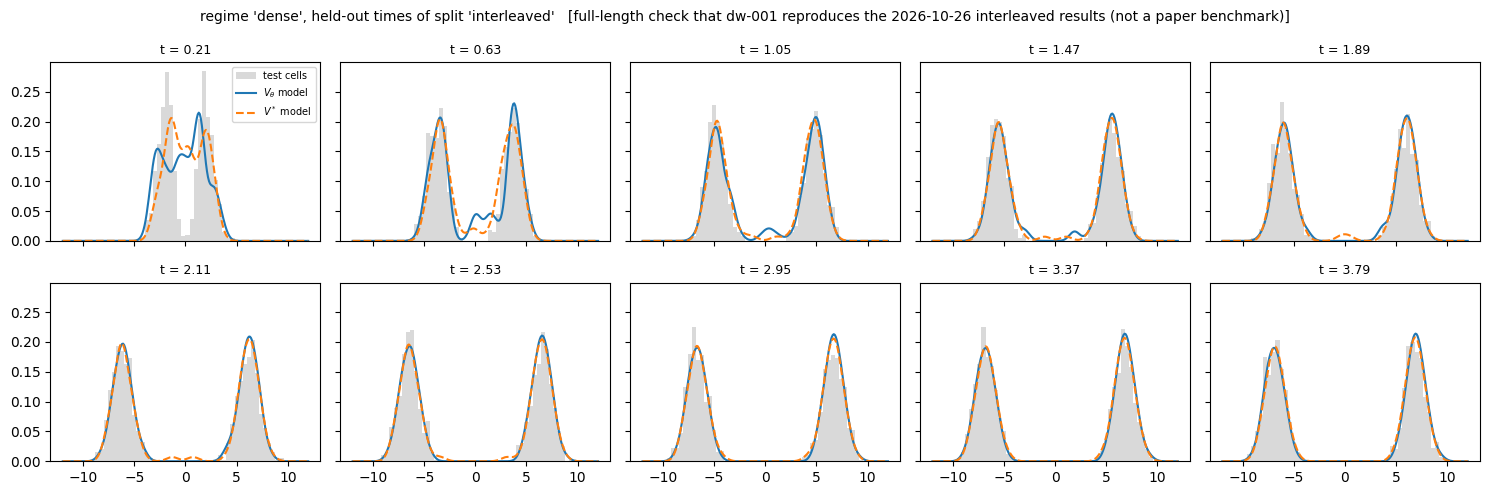

In [9]:
REGIME = "dense"
r = M["regimes"][REGIME]
times = M["times"]
fig, ax = plt.subplots(2, (len(times) + 1) // 2, figsize=(15, 5), sharex=True, sharey=True)
for k, a in enumerate(ax.flat):
    if k >= len(times): a.axis("off"); continue
    a.stairs(M["test_cells"]["hist"][k], M["test_cells"]["hist_edges"], fill=True, color="0.85", label="test cells")
    a.plot(M["density_x"], r["V_theta"]["density"][k], label="$V_\\theta$ model")
    a.plot(M["density_x"], r["V_star"]["density"][k], "--", label="$V^*$ model")
    a.set_title(f"t = {times[k]:.2f}", fontsize=9)
ax.flat[0].legend(fontsize=7)
fig.suptitle(f"regime '{REGIME}', held-out times of split '{M['split']}'   [{cfg['purpose']}]", fontsize=10)
fig.tight_layout()

In [10]:
labels = {k: v["label"] for k, v in M["methods"].items()}
mean = lambda v: sum(v) / len(v)
for metric in ("W1", "W2"):
    print(f"{metric}, mean over the {len(times)} test times")
    print(f"{'regime':9}" + "".join(f"{l:>13}" for l in labels.values()))
    for n, rr in M["regimes"].items():
        print(f"{n:9}" + "".join(f"{mean(rr['scores'][k][metric]):13.3f}" for k in labels))
    print()
for k, v in M["methods"].items():
    print(f"{v['label']:12} {v['kind']:14} {v['dynamics']:8} {v['description']}")

W1, mean over the 10 test times
regime       OT interp  V_theta KDE  V_theta SDE       V* KDE       V* SDE
dense            0.236        0.386        0.461        0.418        0.268
terminal         1.771        1.547        1.378        0.505        0.268
trickle          1.996        0.805        1.243        0.620        2.083

W2, mean over the 10 test times
regime       OT interp  V_theta KDE  V_theta SDE       V* KDE       V* SDE
dense            0.897        1.191        1.325        1.201        0.963
terminal         1.947        1.846        1.566        1.293        0.963
trickle          2.990        2.016        1.618        1.437        3.944

OT interp    OT baseline    none     1-D OT (quantile) interpolation of the two training snapshots that bracket t
V_theta KDE  stitching KDE  learned  samples of the learned model's KDE at t (its fitted particle paths X)
V_theta SDE  SDE rollout    learned  independent rollout of dX = -c_V grad V_theta dt + sqrt(2 c_H) dB from the t

### 7.2 Forces

The learned force $c_V\nabla V_\theta$ for each regime is plotted against the true $\nabla V^*$. The relative error $\lVert c_V\nabla V_\theta-\nabla V^*\rVert/\lVert\nabla V^*\rVert$ is reported both on the test cells and on a uniform grid over $[-10,10]$. The cells are weighted by where the data are; the grid covers everything, including the barrier region the particles cross quickly.

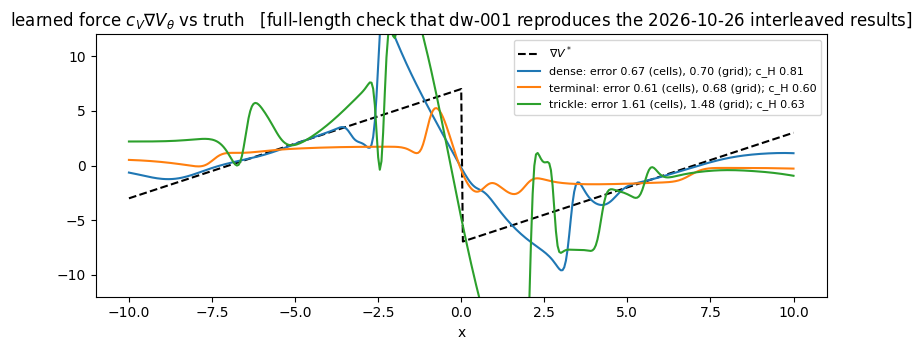

In [11]:
fig, a = plt.subplots(figsize=(8, 3.6))
a.plot(M["true_force"]["x"], M["true_force"]["grad_V"], "k--", lw=1.5, label="$\\nabla V^*$")
for n, rr in M["regimes"].items():
    v = rr["V_theta"]
    a.plot(M["true_force"]["x"], v["force_curve"],
           label=f"{n}: error {v['force_rel_l2_test_cells']:.2f} (cells), {v['force_rel_l2_grid']:.2f} (grid); c_H {v['c_H']:.2f}")
a.set(xlabel="x", ylim=(-12, 12), title=f"learned force $c_V\\nabla V_\\theta$ vs truth   [{cfg['purpose'].split(' (')[0]}]")
a.legend(fontsize=8); fig.tight_layout()

### 7.3 Particle paths and simulated paths: two descriptions of one flow

The left panel shows the stitching model's particle paths, read from the checkpoint and drawn on its internal grid $t_k$. The right panel shows simulated trajectories. They sit in separate panels on purpose: they are not fits of one another. The useful comparison is whether both carry mass into the two wells at the same rate, and section 7.1 already measures that.

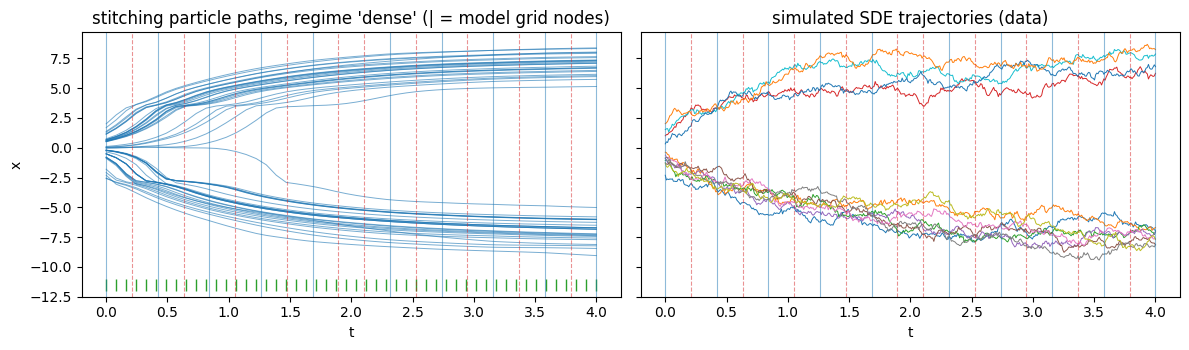

In [12]:
model = load_model(run / "models" / f"{REGIME}_V_theta.pt")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
Xp = model.X.detach()
for k in range(0, Xp.shape[1], 2):
    ax[0].plot(model.t_grid, Xp[:, k, 0], lw=0.7, c="tab:blue", alpha=0.6)
ax[0].plot(model.t_grid, Xp[:, 0, 0] * 0 - 11.5, "|", c="tab:green", ms=8)
ax[0].set(title=f"stitching particle paths, regime '{REGIME}' (| = model grid nodes)", xlabel="t", ylabel="x")
for i in range(ds.paths["X"].shape[1]):
    ax[1].plot(ds.paths["times"], ds.paths["X"][:, i, 0], lw=0.7)
ax[1].set(title="simulated SDE trajectories (data)", xlabel="t")
for a in ax: mark_times(a)
fig.tight_layout()

### Reading these results

- The run above is labelled by its `purpose` field. A short **diagnostic** run (200 epochs) only checks that the pipeline works on every split, and its numbers are not converged results. Full-length numbers and the preserved earlier results are in `experiments/validation/double_well/README.md`.
- Two quantities matter most: how much mass ends up in each well, and the force near the barrier. $W_2$ is dominated by the split of mass between the wells, which are 14 apart, so $W_1$ is often easier to read.
- None of this is a paper benchmark. The double-well is our own additional validation.